# Fase 2 — NER com BERTimbau

Fine-tuning do **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) para reconhecer as entidades
`EXAME`, `VALOR`, `UNIDADE` e `REFERENCIA` em laudos de texto livre (Token Classification, esquema BIO).

A avaliação compara com a linha de base de regex nos splits:
- **teste**: formatos de laudo vistos no treino;
- **teste_ood**: formatos **nunca vistos** (tabela com a referência antes do valor e laudo em várias linhas).

> No Colab: *Ambiente de execução → Alterar o tipo → GPU T4*. Também roda na CPU (~26 min num Ryzen 5 5500).

In [1]:
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("caresync-nlp-core"):
        !git clone -q https://github.com/CSARAIVA06/caresync-nlp-core.git
    %cd caresync-nlp-core
    !pip install -q "transformers>=5" datasets accelerate sentencepiece protobuf seqeval pydantic-settings groq fastapi
else:
    %cd ..
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma (CPU)")

C:\Users\caiof\caresync-nlp-core


GPU: nenhuma (CPU)


## Dataset
Gerado por `scripts/gerar_dataset.py` (seed fixa, reprodutível).

In [2]:
!python scripts/gerar_dataset.py --n 1200 --seed 42

1200 laudos em C:\Users\caiof\caresync-nlp-core\data
split: {'treino': 630, 'teste': 135, 'teste_ood': 300, 'validacao': 135}
risco: {'NORMAL': 387, 'ATENCAO': 417, 'CRITICO': 396}
layout: {'dois_pontos_vr': 150, 'referencia_extenso': 150, 'pontilhado': 150, 'sem_referencia': 150, 'tabela_pipe': 150, 'narrativo': 150, 'tabela_ref_antes': 150, 'multilinha': 150}
entidades: {'EXAME': 4611, 'VALOR': 4611, 'UNIDADE': 4611, 'REFERENCIA': 3470}


## Linha de base: regex + regras

In [3]:
!python scripts/avaliar_regex.py


== teste (135 laudos)
Extração  P=1.000 R=1.000 F1=1.000
  dois_pontos_vr       P=1.000 R=1.000 F1=1.000
  narrativo            P=1.000 R=1.000 F1=1.000
  pontilhado           P=1.000 R=1.000 F1=1.000
  referencia_extenso   P=1.000 R=1.000 F1=1.000
  sem_referencia       P=1.000 R=1.000 F1=1.000
  tabela_pipe          P=1.000 R=1.000 F1=1.000
Triagem   acurácia=1.000 F1-macro=1.000 recall CRITICO=1.000 críticos perdidos=0
  matriz (linhas=real N/A/C, colunas=previsto): [[42, 0, 0], [0, 46, 0], [0, 0, 47]]

== teste_ood (300 laudos)
Extração  P=0.012 R=0.006 F1=0.008
  multilinha           P=0.000 R=0.000 F1=0.000
  tabela_ref_antes     P=0.012 R=0.012 F1=0.012
Triagem   acurácia=0.323 F1-macro=0.180 recall CRITICO=0.000 críticos perdidos=99
  matriz (linhas=real N/A/C, colunas=previsto): [[94, 2, 0], [102, 3, 0], [93, 6, 0]]

Salvo em resultados\baseline_regex.json


## Treinamento do NER

In [ ]:
!python scripts/treinar_ner.py --epocas 4 --lr 5e-5 --batch 8

## Curva de loss

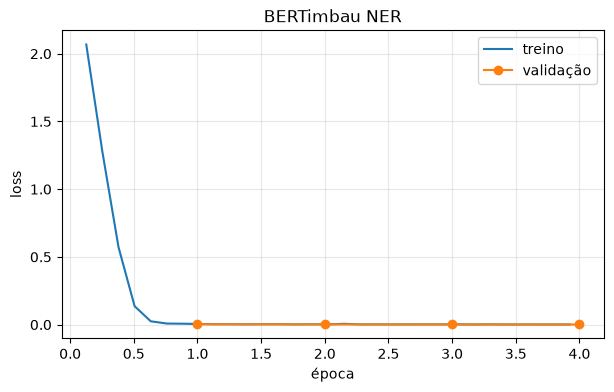

In [4]:
ARQUIVO = "resultados/ner_ner-bertimbau.json"
TITULO = "BERTimbau NER"

import json
import matplotlib.pyplot as plt

res = json.load(open(ARQUIVO, encoding="utf-8"))
hist = res["historico"]
treino = [(h["epoch"], h["loss"]) for h in hist if "loss" in h]
valid = [(h["epoch"], h["eval_loss"]) for h in hist if "eval_loss" in h]

plt.figure(figsize=(7, 4))
plt.plot(*zip(*treino), label="treino")
plt.plot(*zip(*valid), "o-", label="validação")
plt.xlabel("época"); plt.ylabel("loss"); plt.title(TITULO); plt.legend(); plt.grid(alpha=.3)
plt.savefig(ARQUIVO.replace(".json", "_loss.png"), dpi=200, bbox_inches="tight")
plt.show()

## Comparação: regex x NER (pipeline completo até o nível de risco)

In [5]:
import pandas as pd

base = json.load(open("resultados/baseline_regex.json", encoding="utf-8"))
linhas = []
for split in ("teste", "teste_ood"):
    for nome, ext, tri in [
        ("Regex + regras", base[split]["extracao"], base[split]["triagem"]),
        ("NER + regras", res[split]["pipeline_ner_regras"]["extracao"], res[split]["pipeline_ner_regras"]["triagem"]),
    ]:
        linhas.append({"split": split, "sistema": nome, "F1 extração": ext["f1"], "recall extração": ext["recall"],
                       "acurácia risco": tri["acuracia"], "recall CRÍTICO": tri["por_classe"]["CRITICO"]["recall"],
                       "críticos perdidos": tri["criticos_perdidos"]})
pd.DataFrame(linhas).round(3)

,split,sistema,F1 extração,recall extração,acurácia risco,recall CRÍTICO,críticos perdidos
0,teste,Regex + regras,1.000,1.000,1.000,1.000,0
1,teste,NER + regras,0.999,0.998,0.993,0.979,1
2,teste_ood,Regex + regras,0.008,0.006,0.323,0.000,99
3,teste_ood,NER + regras,0.957,0.946,0.960,0.939,6


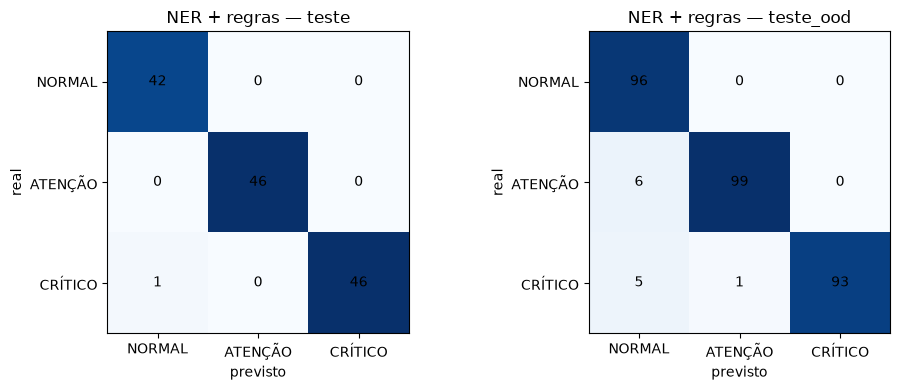

In [6]:
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, split in zip(axes, ("teste", "teste_ood")):
    m = np.array(res[split]["pipeline_ner_regras"]["triagem"]["matriz_confusao"])
    ax.imshow(m, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, m[i, j], ha="center", va="center")
    ax.set_xticks(range(3), ["NORMAL", "ATENÇÃO", "CRÍTICO"]); ax.set_yticks(range(3), ["NORMAL", "ATENÇÃO", "CRÍTICO"])
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(f"NER + regras — {split}")
plt.tight_layout(); plt.savefig("resultados/ner_matriz_confusao.png", dpi=200); plt.show()

## Baixar o modelo treinado
Coloque a pasta em `modelos/ner-bertimbau` e use `EXTRATOR=ner` na API.

In [ ]:
if "google.colab" in sys.modules:
    !zip -qr ner-bertimbau.zip modelos/ner-bertimbau -x "modelos/ner-bertimbau/checkpoints/*"
    from google.colab import files
    files.download("ner-bertimbau.zip")